# Difference between Bagging and Random Forest

1. In bagging we can use any base model that have high variance and low bias (e.g., Decision Trees, SVM, KNN). But in Random Forest we can only use Decision Trees as base model.

2. <text style="color: orange;"> If `max feature` parameter is set to `None` in Random Forest, then it will be same as Bagging with base model as Decision Trees (default base mode of Bagging). But if `max feature` parameter is set to a value less than the total number of features, then it will be different from Bagging. </text>

## How column sampling is different in Random Forest from Bagging?

- In continuation to point 2 above:

- In bagging, column sampling happens in the tree level.
    - i.e Suppose we set `max feature` parameter to 2 in bagging, then for each tree, 2 features will be selected randomly from the total number of features and all the nodes of that tree will use those 2 features to split the data.

- However, in Random Forest, column sampling happens in the node level.
    - i.e Suppose we set `max feature` parameter to 2 in Random Forest, then for each node of each tree, 2 features will be selected randomly from the total number of features and that node will use those 2 features to split the data. So there is more randomness in Random Forest than Bagging.

- So most of the time, Random Forest performs better than Bagging as it has more randomness and hence it is less likely to overfit the training data.

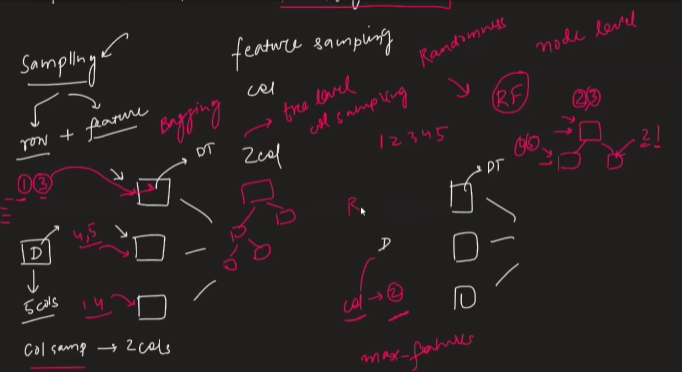

## Why is Randomness Beneficial in Ensemble Learning?

- Randomness introduces **diversity among base models**, making them less correlated with each other.
- When base models make different predictions, their individual errors can cancel out during aggregation (averaging/voting), thereby reducing the overall variance.

**Example:**
- Highly correlated trees: `90, 91, 90, 92` → Predictions are nearly identical, so averaging provides little benefit.
- Less correlated trees: `75, 95, 85, 105` → Predictions vary, allowing individual errors to cancel out during averaging.

**Conclusion:** Randomness helps create diverse, less-correlated base models, making aggregation more effective and improving the ensemble's generalization performance. However, excessive randomness can make individual models too weak.

<text style="color: green;">Random Forest introduces additional randomness by selecting a random subset of features at every split. This reduces correlation among individual Decision Trees. Lower correlation allows aggregation to reduce variance more effectively, improving the overall generalization performance of the ensemble. However, excessive randomness can weaken individual trees. </text>


## Code Example

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.ensemble import BaggingClassifier,RandomForestClassifier
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

In [21]:
X,y = make_classification(n_features=5, n_redundant=0, n_informative=5,n_clusters_per_class=1)

In [22]:
df = pd.DataFrame(X,columns=['col1','col2','col3','col4','col5'])
df['target'] = y
print(df.shape)
df.head()

(100, 6)


,col1,col2,col3,col4,col5,target
0,0.909543,-0.106691,1.670528,-0.757393,0.719450,0
1,0.110632,-0.453240,2.187968,-0.701946,0.129855,0
2,-1.937132,-0.919501,0.892775,1.143991,-0.239039,1
3,3.719366,3.021129,-1.907133,-0.006832,2.674378,0
4,2.122679,3.480089,0.358837,1.516227,0.935520,0


In [23]:
bag = BaggingClassifier(max_features=2)

In [24]:
bag.fit(df.iloc[:,:5],df.iloc[:,-1])

BaggingClassifier(base_estimator=None, bootstrap=True, bootstrap_features=False,
                  max_features=2, max_samples=1.0, n_estimators=10, n_jobs=None,
                  oob_score=False, random_state=None, verbose=0,
                  warm_start=False)

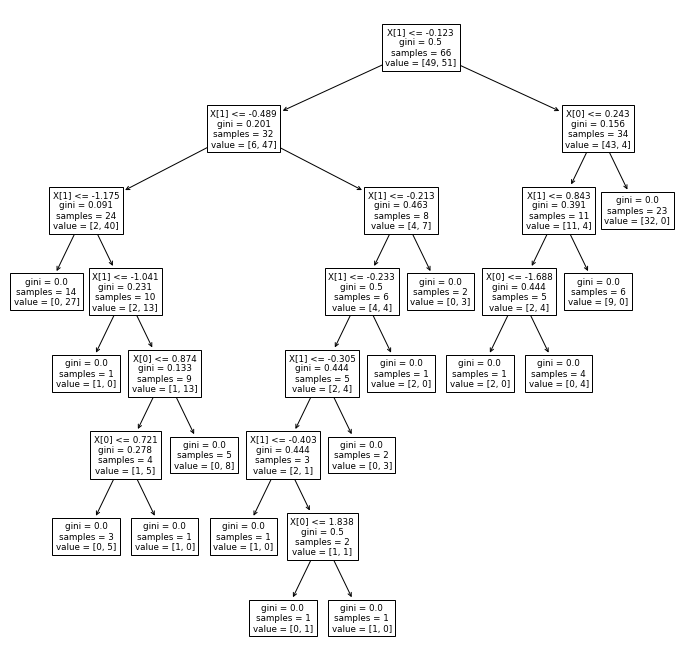

In [25]:
plt.figure(figsize=(12,12))
plot_tree(bag.estimators_[0])
plt.show()

- You can see in all the nodes of the above Bagging algo where desicion tree is used as base model, the same features set (1st and 0th index) are used.

In [26]:
rf = RandomForestClassifier(max_features=2)

In [27]:
rf.fit(df.iloc[:,:5],df.iloc[:,-1])

RandomForestClassifier(bootstrap=True, ccp_alpha=0.0, class_weight=None,
                       criterion='gini', max_depth=None, max_features=2,
                       max_leaf_nodes=None, max_samples=None,
                       min_impurity_decrease=0.0, min_impurity_split=None,
                       min_samples_leaf=1, min_samples_split=2,
                       min_weight_fraction_leaf=0.0, n_estimators=100,
                       n_jobs=None, oob_score=False, random_state=None,
                       verbose=0, warm_start=False)

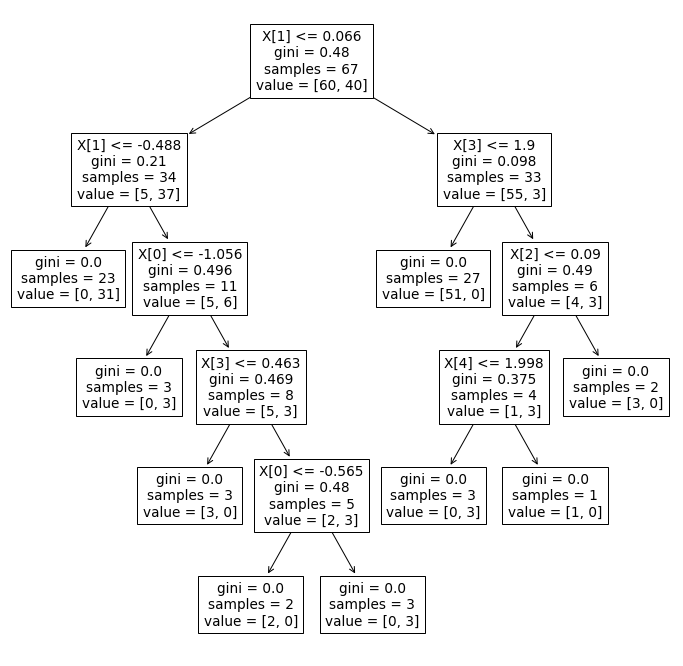

In [28]:
plt.figure(figsize=(12,12))
plot_tree(rf.estimators_[4])
plt.show()

- However, in Random Forest, different features set are used in different nodes of the trees. Hence there is more randomness in Random Forest than Bagging.